#Day 48 Capstone Project - System Recommendation Film ( Content-Based Filtering )

Pernah bertanya-tanya bagaimana Netflix atau Disney+ menyarankan "film yang mungkin kita suka"?

Di capstone ini saya akan membangun **sistem rekomendasi** sederhana namun nyata
memakai pendekatan **content-based filtering**: merekomendasikan film yang **mirip isinya** (genre, kata kunci, sinopsis) dengan film yang kamu sukai.

> 🎯 **Tujuan Pembelajaran**
> - Memahami konsep **content-based recommendation**.
> - Mem-*parse* kolom JSON (genres & keywords) dengan `ast.literal_eval`.
> - Menggabungkan beberapa kolom teks menjadi satu "profil konten" (*tags*).
> - Mengubah teks menjadi angka dengan **TF-IDF**.
> - Mengukur kemiripan film dengan **cosine similarity**.
> - Membungkus semuanya menjadi fungsi `rekomendasi(judul)` yang dapat dipakai.

## About Dataset

Saya akan memakai **TMDB 5000 Movie Metadata** — metadata ~4.800 film dari The Movie Database.

- **Sumber:** [Kaggle — tmdb/tmdb-movie-metadata](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)
- **File:** `tmdb_5000_movies.csv`

| Kolom | Arti |
|-------|------|
| `title` | Judul film |
| `genres` | Genre dalam bentuk **string JSON** (mis. `[{"id":28,"name":"Action"}, ...]`) |
| `keywords` | Kata kunci tema (juga string JSON) |
| `overview` | Sinopsis singkat (teks bebas) |
| `vote_average` | Rata-rata rating penonton |
| `popularity` | Skor popularitas TMDB |

Kolom `genres` & `keywords` terlihat seperti list Python tetapi sebenarnya **teks**.

Saya akan -*parse*-nya untuk mengambil nama genre/keyword.

## Import Library

- **pandas / numpy** → manipulasi data.
- **ast** → mengubah string JSON menjadi objek Python (`literal_eval`).
- **matplotlib / seaborn** → visualisasi.
- **sklearn.feature_extraction.text.TfidfVectorizer** → mengubah teks → vektor angka.
- **sklearn.metrics.pairwise.cosine_similarity** → mengukur kemiripan antar film.

In [1]:
import sys, os, ast

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

## Import Dataset

In [4]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d tmdb/tmdb-movie-metadata
!unzip tmdb-movie-metadata.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata
License(s): other
100% 8.89M/8.89M [00:00<00:00, 89.3MB/s]

Archive:  tmdb-movie-metadata.zip
  inflating: tmdb_5000_credits.csv   
  inflating: tmdb_5000_movies.csv    


In [5]:
df = pd.read_csv('tmdb_5000_movies.csv')

## Early Exploration

Lihat beberapa baris dan kolom yang akan dipakai.

In [6]:
df.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [7]:
use_cols = ['title', 'genres', 'keywords', 'overview', 'vote_average', 'popularity']
df = df[use_cols]
df.head()

,title,genres,keywords,overview,vote_average,popularity
0,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","In the 22nd century, a paraplegic Marine is di...",7.2,150.437577
1,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","Captain Barbossa, long believed to be dead, ha...",6.9,139.082615
2,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",A cryptic message from Bond’s past sends him o...,6.3,107.376788
3,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",Following the death of District Attorney Harve...,7.6,112.312950
4,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 818, ""name"": ""based on novel""}, {""id"":...","John Carter is a war-weary, former military ca...",6.1,43.926995


In [8]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Jumlah data null: {df.isnull().sum().sum()}')


print(f'Jumlah data duplikat: {df.duplicated().sum()}')

Jumlah baris: 4803
Jumlah kolom: 6
Jumlah data null: 3
Jumlah data duplikat: 0


In [9]:
df.isna().sum()

,0
title,0
genres,0
keywords,0
overview,3
vote_average,0
popularity,0


**Interpretasi:**
  - Perhatikan kolom `genres` & `keywords` — isinya berupa **teks** yang menyerupai list of dictionary. Saya belum bisa langsung memakainya; perlu di-*parse* agar bisa mengambil nilai `name` (mis. "Action", "Adventure").
  - Mayoritas kolom lengkap; hanya `overview` yang punya sedikit nilai kosong. Saya akan menggantinya dengan teks kosong agar tidak mengganggu penggabungan.

## Cleaning & Parsing Data Json

Langkah kunci capstone ini. Kolom `genres` & `keywords` adalah string JSON.

Saya akan pakai `ast.literal_eval` untuk mengubahnya menjadi list of dict, lalu ambil semua nilai `name`.

Contoh: `'[{"id":28,"name":"Action"},{"id":12,"name":"Adventure"}]'`
→ menjadi → `["Action", "Adventure"]`.

In [10]:
def take_name(string):
  # Mengubah string JSON menjadi list of dict
  try:
    list_of_dict = ast.literal_eval(string)
    return [d['name'] for d in list_of_dict]
  except(ValueError, SyntaxError, TypeError):
    return []

In [11]:
#drop baris tanpa judul, dan salin
data = df.dropna(subset=['title']).copy( )

In [12]:
data["genre_list"] = data["genres"].apply(take_name)
data["keyword_list"] = data["keywords"].apply(take_name)
data["overview"] = data["overview"].fillna("")

In [13]:
data[["title", "genre_list", "keyword_list", "overview"]].head()

,title,genre_list,keyword_list,overview
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","In the 22nd century, a paraplegic Marine is di..."
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","Captain Barbossa, long believed to be dead, ha..."
2,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...",A cryptic message from Bond’s past sends him o...
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]","[dc comics, crime fighter, terrorist, secret i...",Following the death of District Attorney Harve...
4,John Carter,"[Action, Adventure, Science Fiction]","[based on novel, mars, medallion, space travel...","John Carter is a war-weary, former military ca..."


**Interpretasi:**
  - Berhasil! `genres` & `keywords` kini menjadi **list nama** yang rapi. Sekarang setiap film punya daftar genre dan kata kunci yang bisa digabung menjadi satu deskripsi konten.

### Create Column `tags` ( Merged content profil )

Saya akan gabungkan **genre + keyword + overview** menjadi satu string `tags`.

Untuk genre & keyword yang terdiri dari banyak kata (mis. "Science Fiction"), Saya akan hapus spasi ("ScienceFiction") agar dianggap **satu token utuh** dan tidak tercampur dengan kata lain.

In [14]:
def clean_data(lst):
    return [item.replace(" ", "") for item in lst]

In [15]:
data["tags"] = (
    data["genre_list"].apply(clean_data).apply(lambda x: " ".join(x)) + " " + data["keyword_list"].apply(clean_data).apply(lambda x: " ".join(x)) + " " + data["overview"]
).str.lower()

In [16]:
data = data.reset_index(drop=True)

In [17]:
print("Contoh tags film pertama ('{}'):\n".format(data.loc[0, "title"]))
print(data.loc[0, "tags"][:400], "...")

Contoh tags film pertama ('Avatar'):

action adventure fantasy sciencefiction cultureclash future spacewar spacecolony society spacetravel futuristic romance space alien tribe alienplanet cgi marine soldier battle loveaffair antiwar powerrelations mindandsoul 3d in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. ...


**Interpretasi:**
  - Kolom `tags` kini berisi "sidik jari konten" tiap film: gabungan genre, kata kunci tema, dan sinopsis dalam satu teks huruf kecil. Inilah yang akan diubah menjadi angka.

## Exploratory Data Analysis & Visualization

Sebelum membangun model, mari pahami dulu lanskap data: genre apa yang dominan, dan bagaimana sebaran rating.

### a) 15 Most Popular Genres

In [18]:
from collections import Counter
all_genres = Counter([genre for genres in data["genre_list"] for genre in genres])

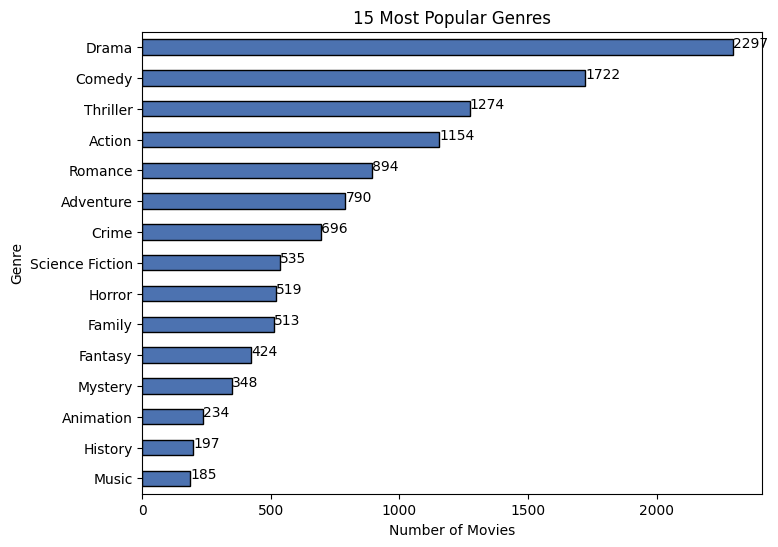

In [19]:
from IPython.terminal.embed import EmbeddedMagics
top_gen = pd.Series(dict(all_genres.most_common(15))).sort_values()

ax = top_gen.plot(kind="barh",
                  color="#4C72B0",
                  edgecolor="black",
                  figsize=(8,6))

plt.title("15 Most Popular Genres")
plt.xlabel("Number of Movies")
for index, value in enumerate(top_gen):
  plt.text(value,
           index,
           str(value))
plt.ylabel("Genre")
plt.show()

**Interpretasi:**
  - **Drama**, **Comedy**, dan **Thriller** mendominasi. Genre populer
ini akan banyak muncul dalam vektor TF-IDF, sehingga TF-IDF (yang memberi bobot lebih rendah pada kata yang umum) membantu menonjolkan ciri yang lebih khas tiap film.

### b) Distribution of audience ratings (vote_average)

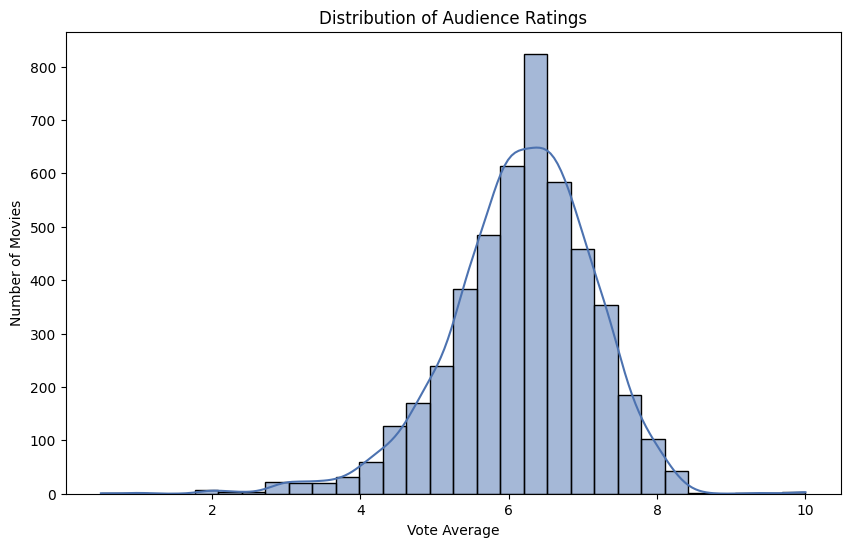

In [20]:
# Fokus pada film yang punya cukup suara agar rating bermakna
plt.figure(figsize=(10, 6))
sns.histplot(data[data["vote_average"]>0]["vote_average"],
             bins=30,
             color="#4C72B0",
             kde=True)
plt.title("Distribution of Audience Ratings")
plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")
plt.show()

**Interpretasi:**
  - Mayoritas film berkumpul di rating 6–7 — pola umum platform film (sangat sedikit yang sangat buruk atau sempurna). Rating ini bisa dipakai sebagai "penyaring kualitas" tambahan pada rekomendasi (latihan di akhir).

### c) Synopsis length (number of words in the overview)

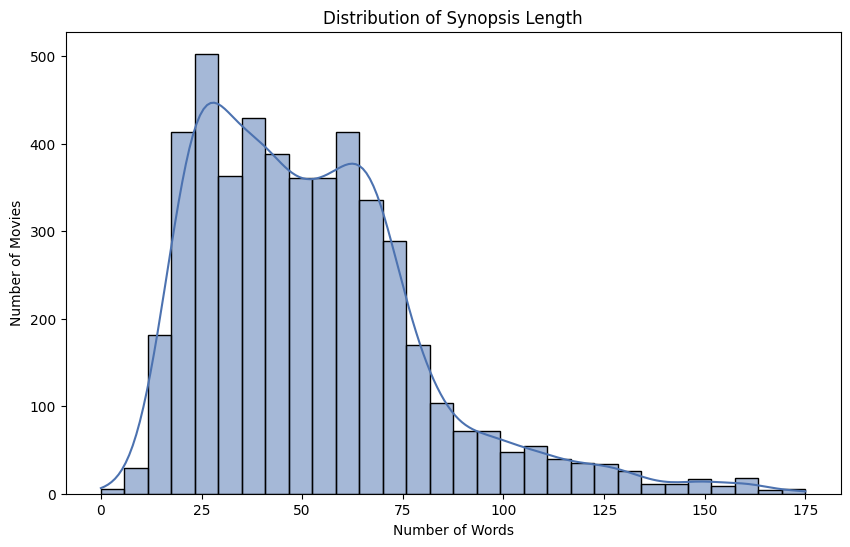

In [21]:
data["len_ovrw"] = data["overview"].str.split().apply(len)

plt.figure(figsize=(10, 6))
sns.histplot(data["len_ovrw"],
             bins=30,
             color="#4C72B0",
             kde=True)
plt.title("Distribution of Synopsis Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Movies")
plt.show()

**Interpretasi:**
  - Sebagian besar sinopsis berisi ~20–50 kata. Sinopsis yang sangat pendek memberi sedikit sinyal konten — film seperti ini akan lebih bergantung pada genre & keyword saat dicari kemiripannya.

### d) Highest-rated films (with a sufficient number of votes)

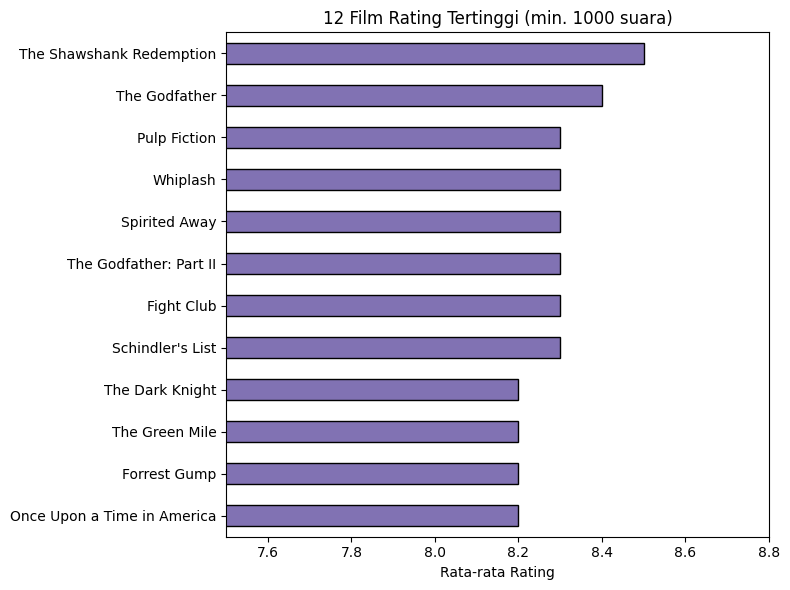

In [24]:
# Load 'vote_count' back from the original CSV to fix the missing column error
temp_df = pd.read_csv('tmdb_5000_movies.csv')[['title', 'vote_count']]
data_with_votes = data.merge(temp_df, on='title', how='left')

populer = data_with_votes[data_with_votes["vote_count"] >= 1000].nlargest(12, "vote_average")

ax = populer.set_index("title")["vote_average"].sort_values().plot(
    kind="barh", color="#8172B3", edgecolor="black", figsize=(8, 6))

plt.title("12 Film Rating Tertinggi (min. 1000 suara)")
plt.xlabel("Rata-rata Rating"); plt.ylabel("")
plt.xlim(7.5, 8.8)

plt.tight_layout()
plt.show()

**Interpretasi:**
  - Film-film klasik & kritis (mis. *The Shawshank Redemption*,*The Godfather*) menempati rating teratas. Daftar ini berguna sebagai **fallback
rekomendasi** ("film terbaik sepanjang masa") ketika sistem belum punya cukup konteks
tentang selera pengguna.

## TF-IDF: Converting Text into Numbers

Komputer tidak mengerti kata; ia butuh angka. **TF-IDF** (Term Frequency–Inverse
Document Frequency) memberi skor tiap kata:

  - **Tinggi** bila kata sering muncul di satu film **tapi jarang** di film lain (kata khas).
  - **Rendah** bila kata muncul di mana-mana (kata umum, kurang membedakan).

Saya akan batasi ke 5.000 kata terpenting dan buang *stop words* bahasa Inggris.

In [27]:
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)

tfidf_matrix = tfidf.fit_transform(data["tags"])

print('Bentuk Matrik TFIDF:', tfidf_matrix.shape)
print('Jumlah Film x Jumlah kata terpilih')

Bentuk Matrik TFIDF: (4803, 5000)
Jumlah Film x Jumlah kata terpilih


**Interpretasi:**
  -  Saya saat ini punya matriks berukuran ~4.800 film × 5.000 kata. Setiap film direpresentasikan sebagai **vektor** di ruang 5.000 dimensi — semakin mirip arah vektor dua film, semakin mirip kontennya.

## Consine Similarity : Measuring Similarity

**Cosine similarity** mengukur sudut antara dua vektor. Nilainya 0 (tak mirip) hingga 1 (identik). Saya akan hitung kemiripan **setiap film terhadap semua film lain**.

In [28]:
similarity = cosine_similarity(tfidf_matrix)
print('Bentuk Matrik Kemiripan:', similarity.shape)
print('Jumlah Film x Jumlah Film')

Bentuk Matrik Kemiripan: (4803, 4803)
Jumlah Film x Jumlah Film


In [29]:
# Peta dari judul -> index baris (judul huruf kecil agar pencarian fleksibel)
idx = pd.Series(data.index, index=data["title"].str.lower())

# Buang duplikat judul (ambil yang pertama)
idx = idx[~idx.index.duplicated(keep='first')]

# Contoh
idx.head()


,0
title,
avatar,0
pirates of the caribbean: at world's end,1
spectre,2
the dark knight rises,3
john carter,4


In [30]:
print("Contoh kemiripan film 0 dengan 5 film pertama:", similarity[0][:5].round(3))

Contoh kemiripan film 0 dengan 5 film pertama: [1.    0.024 0.013 0.021 0.104]


**Interpretasi:**
  - Matriks `similarity` berukuran N×N: sel (i, j) = kemiripan film i
dengan film j. Diagonalnya bernilai 1 (film mirip 100% dengan dirinya sendiri).

Inilah "mesin" rekomendasi saya.

## Recommendation Function

Sekarang saya akan bungkus semuanya menjadi fungsi `rekomendasi(judul, n=5)`:

1. Cari index film berdasarkan judul (tahan terhadap huruf besar/kecil).
2. Ambil baris kemiripannya, urutkan dari paling mirip.
3. Lewati film itu sendiri, kembalikan `n` teratas.
4. Tangani kasus judul tidak ditemukan.

In [35]:
def rekomendasi(judul, n=5):
    """Mengembalikan n film paling mirip dengan `judul` (content-based)."""
    kunci = judul.strip().lower()
    if kunci not in idx:
        # Coba pencarian sebagian (substring) untuk membantu pengguna
        cocok = [t for t in idx.index if kunci in t]
        if not cocok:
            return f"Maaf, film '{judul}' tidak ditemukan di dataset."
        kunci = cocok[0]  # pakai kecocokan pertama

    indx = idx[kunci]
    skor = list(enumerate(similarity[indx]))
    skor = sorted(skor, key=lambda x: x[1], reverse=True)
    skor = skor[1:n + 1]   # lewati diri sendiri (indeks 0 setelah sort)

    hasil = pd.DataFrame({
        "Judul": [data.loc[i, "title"] for i, _ in skor],
        "Genre": [", ".join(data.loc[i, "genre_list"][:3]) for i, _ in skor],
        "Rating": [data.loc[i, "vote_average"] for i, _ in skor],
        "Kemiripan": [round(s, 3) for _, s in skor],
    })
    return hasil

print("Fungsi rekomendasi siap dipakai!")

Fungsi rekomendasi siap dipakai!


## Demo: Try Out Several Titles

Saatnya membuktikan sistemnya bekerja. Saya akan mencoba beberapa film terkenal.

### Recommendations for *Avatar*

In [36]:
rekomendasi('Avatar')

,Judul,Genre,Rating,Kemiripan
0,Falcon Rising,"Adventure, Action",5.5,0.207
1,Battle: Los Angeles,"Action, Science Fiction",5.5,0.193
2,Apollo 18,"Horror, Thriller, Science Fiction",5.0,0.187
3,Titan A.E.,"Animation, Action, Science Fiction",6.3,0.182
4,Predators,"Action, Science Fiction, Adventure",6.0,0.168


**Interpretasi:**
  - Rekomendasi untuk *Avatar* didominasi film **fiksi ilmiah / petualangan epik** dengan tema luar angkasa & dunia asing — persis nuansa Avatar. Sistem menangkap "DNA konten" film dengan baik.

### Recommendations for *The Dark Knight*

In [37]:
rekomendasi('The Dark Knight')

,Judul,Genre,Rating,Kemiripan
0,The Dark Knight Rises,"Action, Crime, Drama",7.6,0.468
1,Batman Returns,"Action, Fantasy",6.6,0.398
2,Batman Forever,"Action, Crime, Fantasy",5.2,0.337
3,Batman Begins,"Action, Crime, Drama",7.5,0.324
4,"Batman: The Dark Knight Returns, Part 2","Action, Animation",7.9,0.296


**Interpretasi:**
  - Untuk *The Dark Knight*, sistem menyodorkan film **aksi/kriminal bertema superhero & penjahat** — banyak di antaranya film Batman lain atau bertema serupa. Genre + keyword "dc comics / superhero / crime" mendorong kemiripan tinggi.

### Rekomendasi untuk *The Avengers*

In [38]:
rekomendasi('The Avengers')

,Judul,Genre,Rating,Kemiripan
0,Avengers: Age of Ultron,"Action, Adventure, Science Fiction",7.3,0.277
1,Ant-Man,"Science Fiction, Action, Adventure",7.0,0.222
2,Captain America: The First Avenger,"Action, Adventure, Science Fiction",6.6,0.219
3,Thor: The Dark World,"Action, Adventure, Fantasy",6.8,0.214
4,Iron Man 3,"Action, Adventure, Science Fiction",6.8,0.205


**Interpretasi:**
  - Hasilnya didominasi film **superhero Marvel** dan aksi tim — sangat relevan. Ini menunjukkan kekuatan content-based: tanpa data perilaku pengguna sekalipun, kita bisa merekomendasikan dari **isi** film saja.

## Kesimpulan & Insight


### 1. Rekapitulasi Alur Sistem
Sistem rekomendasi film yang dibangun menggunakan pendekatan **Content-Based Filtering** dengan alur kerja berikut:
- **Data Cleaning & Parsing:** Mengonversi representasi string JSON pada kolom `genres` dan `keywords` menjadi list objek Python menggunakan `ast.literal_eval`.
- **Feature Engineering (`tags`):** Menggabungkan kolom `genre_list` (yang telah dihapus spasinya), `keyword_list`, dan sinopsis (`overview`) menjadi satu kesatuan dokumen teks representatif untuk setiap film.
- **Vektorisasi TF-IDF:** Mengubah dokumen teks (`tags`) menjadi representasi numerik multidimensi (matriks berukuran 4803 film x 5000 kata penting) dengan pembobotan kata berbasis keunikan dokumen.
- **Pengukuran Kemiripan (Cosine Similarity):** Menghitung nilai kosinus sudut antar-vektor untuk mendapatkan derajat kemiripan numerik (skala 0 hingga 1) antar-film.

### 2. Insight Utama dari EDA
- **Dominasi Genre:** Dataset ini sangat didominasi oleh genre **Drama** (2297 film), **Comedy** (1722 film), dan **Thriller** (1274 film). Algoritma TF-IDF sangat krusial di sini karena dapat menekan bobot kata-kata yang terlalu umum (seperti nama genre populer ini) dan menonjolkan kata kunci yang lebih spesifik.
- **Distribusi Rating & Sinopsis:** Mayoritas rating film terpusat di angka 6-7. Panjang sinopsis dominan berkisar antara 20–50 kata, yang berarti kualitas metadata genre dan kata kunci sangat menentukan akurasi pencarian kemiripan bagi film dengan sinopsis pendek.

### 3. Analisis Hasil Rekomendasi (Evaluasi Kualitatif)
Sistem berhasil memberikan rekomendasi yang sangat relevan dan logis secara kontekstual:
- **Kasus *Avatar*:** Memberikan film-film sci-fi petualangan luar angkasa bernuansa mirip seperti *Battle: Los Angeles* dan *Predators*.
- **Kasus *The Dark Knight*:** Menampilkan sekuel/prekuel langsung (*The Dark Knight Rises*, *Batman Begins*) serta adaptasi superhero DC lainnya.
- **Kasus *The Avengers*:** Berhasil mengelompokkan sesama film Marvel Cinematic Universe (MCU) karena kemiripan entitas karakter dan tema aksi pahlawan super.

### 4. Peluang Pengembangan ke Depan
Sistem sederhana ini dapat ditingkatkan lebih lanjut dengan beberapa strategi:
1. **Weighted Hybrid Rating:** Mengintegrasikan faktor popularitas dan rating (`vote_average` & `vote_count`) menggunakan formula *Bayesian Average* milik IMDB agar film yang direkomendasikan tidak hanya mirip, tetapi juga memiliki kualitas yang diakui penonton.
2. **Collaborative Filtering:** Menggabungkan data preferensi atau interaksi pengguna (user-rating matrix) untuk mengatasi kelemahan content-based filtering (seperti masalah *filter bubble* atau rekomendasi yang terlalu monoton).
3. **Metadata Expansion:** Menambahkan bobot lebih tinggi pada sutradara (*director*) atau jajaran pemain utama (*cast*) yang sering kali menjadi faktor penentu utama seseorang dalam memilih film.